In [1]:
%pip install tensorflow numpy matplotlib pandas seaborn 

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, models
from tensorflow.keras.callbacks import EarlyStopping
import seaborn as sns

In [3]:
data = np.load('cifar-10-python.npz')

X_train = data["x_train"]
y_train = data["y_train"]
X_test = data["x_test"]
y_test = data["y_test"]

print("Training images:", X_train.shape)
print("Training labels:", y_train.shape)
print("Testing images:", X_test.shape)
print("Testing labels:", y_test.shape)

Training images: (50000, 32, 32, 3)
Training labels: (50000,)
Testing images: (10000, 32, 32, 3)
Testing labels: (10000,)


In [4]:
m, n = np.max(X_train), np.min(X_train)
normalised_value = m - n

print(f"Max pixel value: {m}")
print(f"Min pixel value: {n}")

X_train, X_test = X_train / normalised_value, X_test / normalised_value

print("Pixel range:", X_train.min(), "to", X_train.max())

Max pixel value: 255
Min pixel value: 0
Pixel range: 0.0 to 1.0


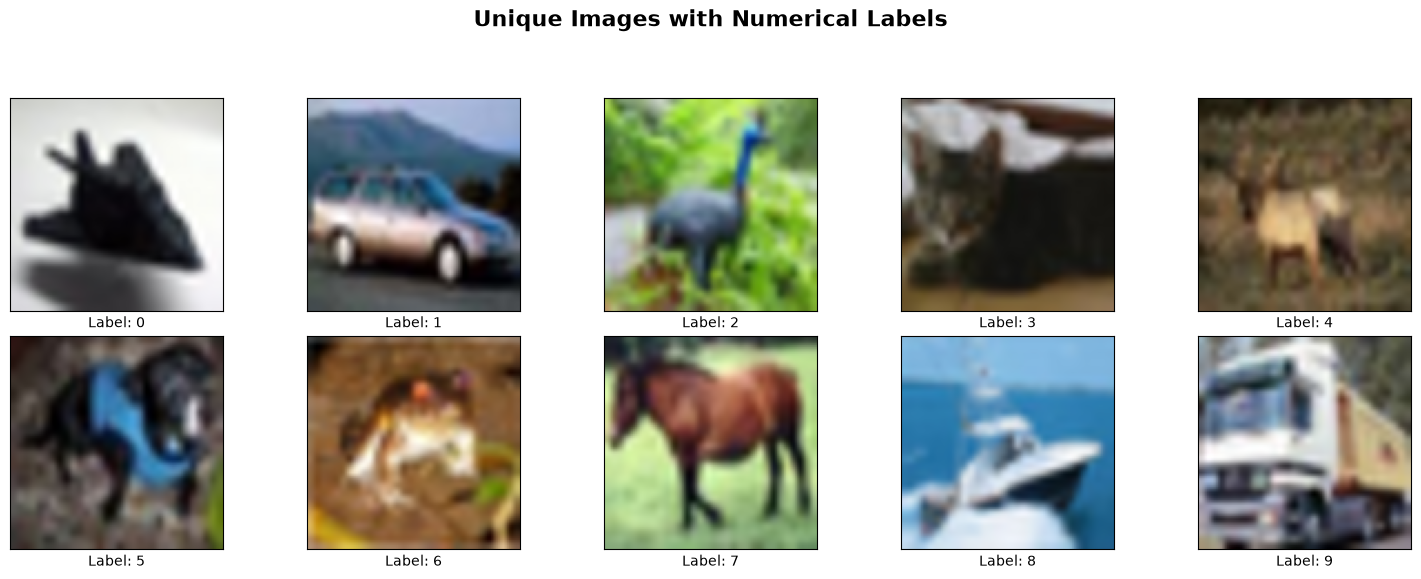

In [5]:
unique_labels, unique_indices = np.unique(
    y_train.flatten(), return_index=True
)

plt.figure(figsize=(15, 6))
plt.suptitle(
    "Unique Images with Numerical Labels",
    fontsize=16,
    fontweight="bold"
)

for i, label in enumerate(unique_labels):
    index = unique_indices[i]

    upscaled_image = tf.image.resize(
        X_train[index], (96, 96), method="bicubic"
    ).numpy()

    clipped_image = np.clip(upscaled_image, 0, 1)

    plt.subplot(2, 5, i + 1)
    plt.imshow(clipped_image)
    plt.xticks([])
    plt.yticks([])
    plt.xlabel(f"Label: {int(label)}")
    plt.grid(False)

plt.tight_layout(rect=[0, 0.03, 1, 0.92])
plt.show()

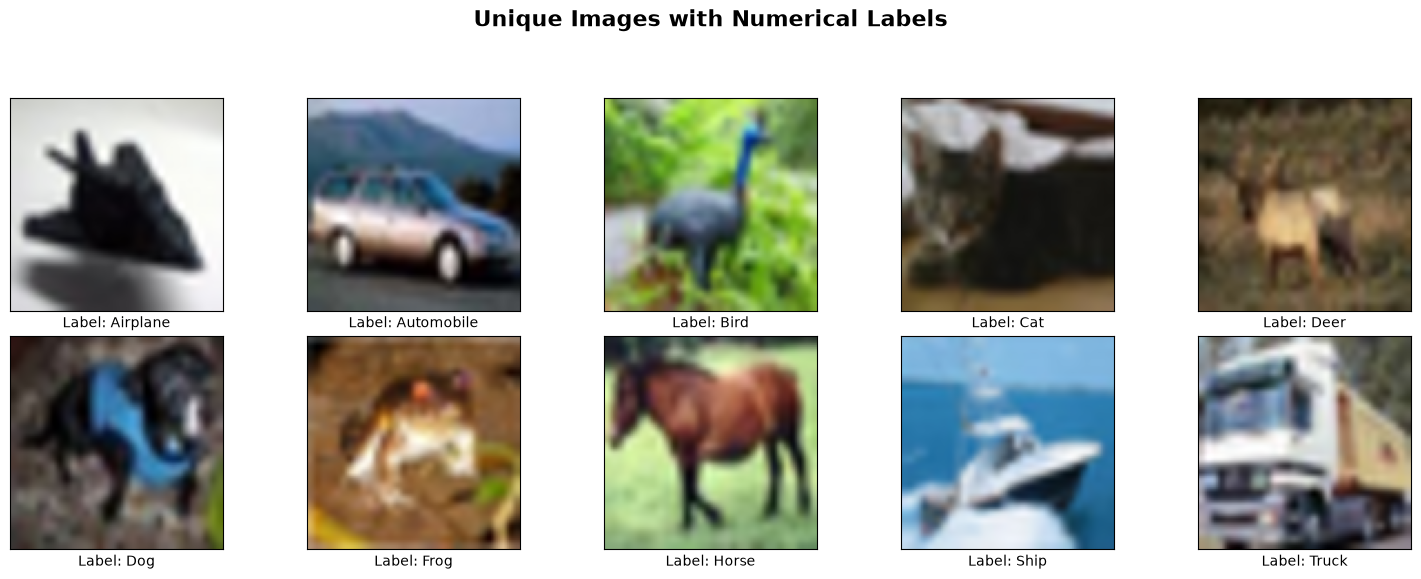

In [6]:
class_names = ["Airplane", "Automobile", "Bird", "Cat", "Deer",
               "Dog", "Frog", "Horse", "Ship", "Truck"]
unique_labels, unique_indices = np.unique(
    y_train.flatten(), return_index=True
)

plt.figure(figsize=(15, 6))
plt.suptitle(
    "Unique Images with Numerical Labels",
    fontsize=16,
    fontweight="bold"
)

for i, label in enumerate(unique_labels):
    index = unique_indices[i]

    upscaled_image = tf.image.resize(
        X_train[index], (96, 96), method="bicubic"
    ).numpy()

    clipped_image = np.clip(upscaled_image, 0, 1)

    plt.subplot(2, 5, i + 1)
    plt.imshow(clipped_image)
    plt.xticks([])
    plt.yticks([])
    plt.xlabel(f"Label: {class_names[int(label)]}")
    plt.grid(False)

plt.tight_layout(rect=[0, 0.03, 1, 0.92])
plt.show()

In [7]:
data_augmentation = keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.05),
    layers.RandomTranslation(
        height_factor=0.1,
        width_factor=0.1
    ),
    layers.RandomZoom(0.1)
])

In [8]:
model1 = models.Sequential(
    [
        layers.Input(shape=(32, 32, 3)),

        data_augmentation,

        layers.Resizing(64, 64, interpolation="bilinear"),

        layers.Conv2D(32, (3, 3), activation="relu"),
        layers.MaxPooling2D((2, 2)),
        layers.Flatten(),
        layers.Dense(64, activation="relu"),
        layers.Dense(10, activation="softmax"),
    ]
)

model1.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ sequential (Sequential)              │ (None, 32, 32, 3)           │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ resizing (Resizing)                  │ (None, 64, 64, 3)           │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d (Conv2D)                      │ (None, 62, 62, 32)          │             896 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d (MaxPooling2D)         │ (None, 31, 31, 32)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ flatten (Flatten)                    │ (None, 30752)               │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ (None, 64)                  │       1,968,192 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 10)                  │             650 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 1,969,738 (7.51 MB)

 Trainable params: 1,969,738 (7.51 MB)

 Non-trainable params: 0 (0.00 B)

In [9]:
model2 = keras.Sequential([
    layers.Input(shape=(32, 32, 3)),

    data_augmentation,

    layers.Resizing(64, 64, interpolation="bilinear"),

    layers.Conv2D(32, (3, 3), padding="same", activation="relu"),
    layers.Conv2D(32, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),
    layers.Dropout(0.25),

    layers.Conv2D(64, (3, 3), padding="same", activation="relu"),
    layers.Conv2D(64, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),
    layers.Dropout(0.25),

    layers.Flatten(),
    layers.Dense(128, activation="relu"),
    layers.Dropout(0.5),
    layers.Dense(10, activation="softmax")
])

model2.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ sequential (Sequential)              │ (None, 32, 32, 3)           │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ resizing_1 (Resizing)                │ (None, 64, 64, 3)           │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_1 (Conv2D)                    │ (None, 64, 64, 32)          │             896 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_2 (Conv2D)                    │ (None, 62, 62, 32)          │           9,248 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_1 (MaxPooling2D)       │ (None, 31, 31, 32)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout (Dropout)                    │ (None, 31, 31, 32)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_3 (Conv2D)                    │ (None, 31, 31, 64)          │          18,496 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_4 (Conv2D)                    │ (None, 29, 29, 64)          │          36,928 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_2 (MaxPooling2D)       │ (None, 14, 14, 64)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_1 (Dropout)                  │ (None, 14, 14, 64)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ flatten_1 (Flatten)                  │ (None, 12544)               │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_2 (Dense)                      │ (None, 128)                 │       1,605,760 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_2 (Dropout)                  │ (None, 128)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_3 (Dense)                      │ (None, 10)                  │           1,290 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 1,672,618 (6.38 MB)

 Trainable params: 1,672,618 (6.38 MB)

 Non-trainable params: 0 (0.00 B)

In [10]:
model1.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

model2.compile(
    optimizer=keras.optimizers.SGD(learning_rate=0.01, momentum=0.9),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

In [11]:
early_stop1 = EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True,
    verbose=1
)

history1 = model1.fit(
    X_train, y_train,
    epochs=10,
    batch_size=64,
    validation_split=0.1,
    callbacks=[early_stop1]
)
history2 = model2.fit(
    X_train, y_train,
    epochs=10,
    batch_size=64,
    validation_split=0.1,
    callbacks=[early_stop1]
)

Epoch 1/10
704/704 ━━━━━━━━━━━━━━━━━━━━ 17s 23ms/step - accuracy: 0.3684 - loss: 1.7559 - val_accuracy: 0.4486 - val_loss: 1.5506
Epoch 2/10
704/704 ━━━━━━━━━━━━━━━━━━━━ 17s 24ms/step - accuracy: 0.4412 - loss: 1.5606 - val_accuracy: 0.4682 - val_loss: 1.5113
Epoch 3/10
704/704 ━━━━━━━━━━━━━━━━━━━━ 16s 23ms/step - accuracy: 0.4609 - loss: 1.5089 - val_accuracy: 0.4604 - val_loss: 1.5661
Epoch 4/10
704/704 ━━━━━━━━━━━━━━━━━━━━ 16s 23ms/step - accuracy: 0.4784 - loss: 1.4634 - val_accuracy: 0.5104 - val_loss: 1.4221
Epoch 5/10
704/704 ━━━━━━━━━━━━━━━━━━━━ 16s 23ms/step - accuracy: 0.4871 - loss: 1.4318 - val_accuracy: 0.5476 - val_loss: 1.2896
Epoch 6/10
704/704 ━━━━━━━━━━━━━━━━━━━━ 16s 23ms/step - accuracy: 0.4996 - loss: 1.4032 - val_accuracy: 0.5372 - val_loss: 1.3275
Epoch 7/10
704/704 ━━━━━━━━━━━━━━━━━━━━ 16s 23ms/step - accuracy: 0.5079 - loss: 1.3787 - val_accuracy: 0.5174 - val_loss: 1.3961
Epoch 8/10
704/704 ━━━━━━━━━━━━━━━━━━━━ 16s 23ms/step - accuracy: 0.5114 - loss: 1.3692 - 

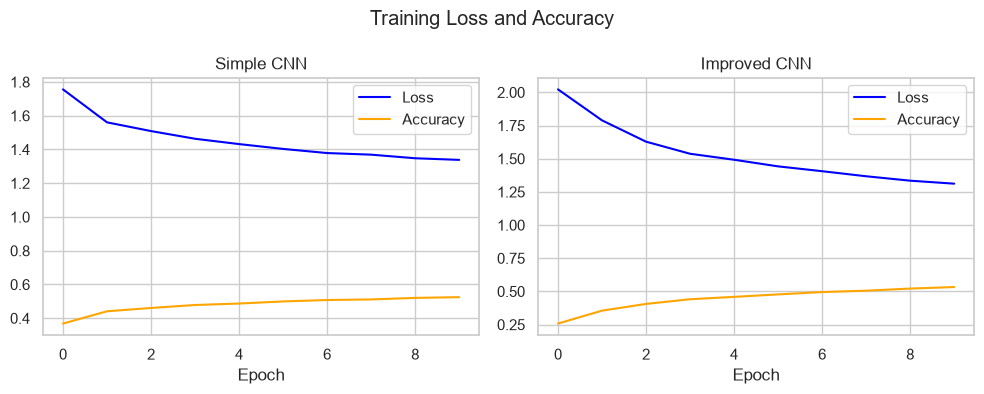

In [12]:
sns.set_theme(style="whitegrid")

fig, axes = plt.subplots(1, 2, figsize=(10, 4))

axes[0].plot(history1.history["loss"], color="blue", label="Loss")
axes[0].plot(history1.history["accuracy"], color="orange", label="Accuracy")
axes[0].set_title("Simple CNN")
axes[0].set_xlabel("Epoch")
axes[0].legend()

axes[1].plot(history2.history["loss"], color="blue", label="Loss")
axes[1].plot(history2.history["accuracy"], color="orange", label="Accuracy")
axes[1].set_title("Improved CNN")
axes[1].set_xlabel("Epoch")
axes[1].legend()

fig.suptitle("Training Loss and Accuracy")
plt.tight_layout()
plt.show()

In [13]:
test_loss1, test_acc1 = model1.evaluate(X_test, y_test, verbose=0)
test_loss2, test_acc2 = model2.evaluate(X_test, y_test, verbose=0)

print("Simple CNN")
print(f"Test Loss: {test_loss1:.4f}")
print(f"Test Accuracy: {test_acc1 * 100:.2f}%")

print("\nImproved CNN")
print(f"Test Loss: {test_loss2:.4f}")
print(f"Test Accuracy: {test_acc2 * 100:.2f}%")

Simple CNN
Test Loss: 1.3036
Test Accuracy: 53.59%

Improved CNN
Test Loss: 1.0832
Test Accuracy: 61.14%


In [14]:
results = pd.DataFrame({
    "Model": ["Simple CNN", "Improved CNN"],
    "Test Loss": [test_loss1, test_loss2],
    "Test Accuracy (%)": [test_acc1 * 100, test_acc2 * 100]
})

print(results.round(2).to_string(index=False))

       Model  Test Loss  Test Accuracy (%)
  Simple CNN       1.30              53.59
Improved CNN       1.08              61.14


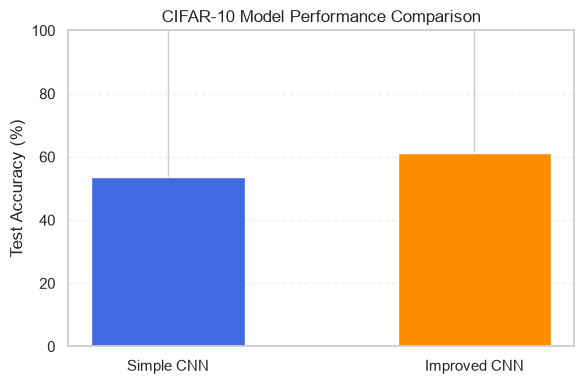

In [15]:
plt.figure(figsize=(6, 4))

plt.bar(
    ["Simple CNN", "Improved CNN"],
    [test_acc1 * 100, test_acc2 * 100],
    color=["royalblue", "darkorange"],
    width=0.5
)

plt.ylabel("Test Accuracy (%)")
plt.title("CIFAR-10 Model Performance Comparison")
plt.ylim(0, 100)
plt.grid(axis="y", linestyle="--", alpha=0.3)
plt.tight_layout()
plt.show()

In [16]:
if test_acc1 > test_acc2:
    print("Simple CNN performs better.")
elif test_acc2 > test_acc1:
    print("Improved CNN performs better.")
else:
    print("Both models have the same test accuracy.")

Improved CNN performs better.


Enter an index between 0 and 9999:  5


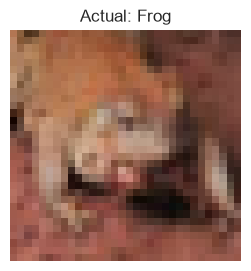

Actual Class: Frog

Model 1: Simple CNN
Predicted Class: Frog
Confidence: 56.63%
Correct Prediction!

Model 2: Improved CNN
Predicted Class: Frog
Confidence: 86.87%
Correct Prediction!


In [17]:
index = int(input("Enter an index between 0 and 9999: "))

if 0 <= index < len(X_test):

    image = X_test[index]
    actual_label = int(y_test[index].flatten()[0])

    pred1 = model1.predict(image.reshape(1, 32, 32, 3), verbose=0)
    pred2 = model2.predict(image.reshape(1, 32, 32, 3), verbose=0)

    predicted1 = np.argmax(pred1[0])
    predicted2 = np.argmax(pred2[0])

    plt.figure(figsize=(3, 3))
    plt.imshow(image)
    plt.title(f"Actual: {class_names[actual_label]}")
    plt.axis("off")
    plt.show()

    print("Actual Class:", class_names[actual_label])
    print("\nModel 1: Simple CNN")
    print("Predicted Class:", class_names[predicted1])
    print(f"Confidence: {np.max(pred1[0]) * 100:.2f}%")
    print("Correct Prediction!" if predicted1 == actual_label
          else "Incorrect Prediction!")

    print("\nModel 2: Improved CNN")
    print("Predicted Class:", class_names[predicted2])
    print(f"Confidence: {np.max(pred2[0]) * 100:.2f}%")
    print("Correct Prediction!" if predicted2 == actual_label
          else "Incorrect Prediction!")

else:
    print("Invalid index! Enter a number from 0 to 9999.")

# Part 2: The same two CNN models on the MNIST dataset

Everything below is new. It repeats the CIFAR-10 steps above on `mnist.npz`.
All new variables end in `_mnist`, so the CIFAR-10 results above are not overwritten.

In [18]:
# Load MNIST from the project directory
data_mnist = np.load('mnist.npz')

X_train_mnist = data_mnist["x_train"]
y_train_mnist = data_mnist["y_train"]
X_test_mnist = data_mnist["x_test"]
y_test_mnist = data_mnist["y_test"]

print("Training images:", X_train_mnist.shape)
print("Training labels:", y_train_mnist.shape)
print("Testing images:", X_test_mnist.shape)
print("Testing labels:", y_test_mnist.shape)

Training images: (60000, 28, 28)
Training labels: (60000,)
Testing images: (10000, 28, 28)
Testing labels: (10000,)


In [19]:
# Normalize using min-max range
m, n = np.max(X_train_mnist), np.min(X_train_mnist)
normalised_value = m - n

print(f"Max pixel value: {m}")
print(f"Min pixel value: {n}")

X_train_mnist = X_train_mnist / normalised_value
X_test_mnist = X_test_mnist / normalised_value

# MNIST is grayscale (28, 28). Conv2D needs a channel axis, so make it (28, 28, 1)
X_train_mnist = X_train_mnist.reshape(-1, 28, 28, 1)
X_test_mnist = X_test_mnist.reshape(-1, 28, 28, 1)

print("Pixel range:", X_train_mnist.min(), "to", X_train_mnist.max())
print("New training shape:", X_train_mnist.shape)
print("New testing shape:", X_test_mnist.shape)

Max pixel value: 255
Min pixel value: 0
Pixel range: 0.0 to 1.0
New training shape: (60000, 28, 28, 1)
New testing shape: (10000, 28, 28, 1)


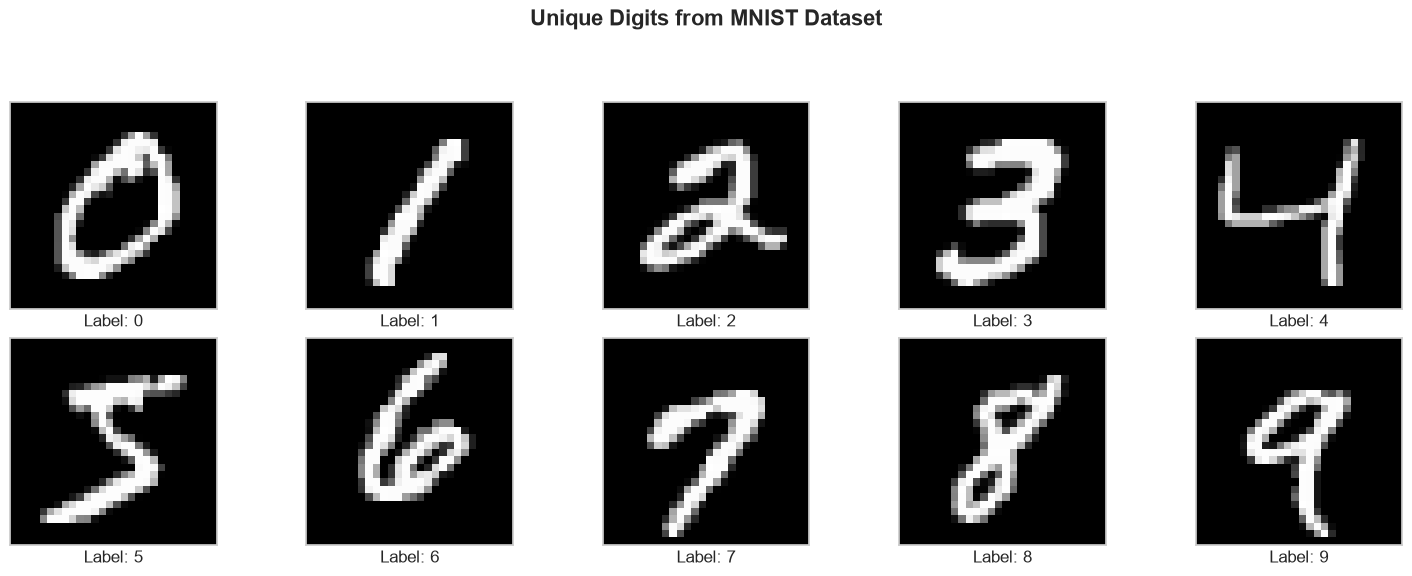

In [20]:
# Show the first image of each digit
unique_labels_mnist, unique_indices_mnist = np.unique(
    y_train_mnist.flatten(), return_index=True
)

plt.figure(figsize=(15, 6))
plt.suptitle(
    "Unique Digits from MNIST Dataset",
    fontsize=16,
    fontweight="bold"
)

for i, label in enumerate(unique_labels_mnist):
    index = unique_indices_mnist[i]

    plt.subplot(2, 5, i + 1)
    plt.imshow(X_train_mnist[index].reshape(28, 28), cmap="gray")
    plt.xticks([])
    plt.yticks([])
    plt.xlabel(f"Label: {int(label)}")
    plt.grid(False)

plt.tight_layout(rect=[0, 0.03, 1, 0.92])
plt.show()

In [21]:
# Augmentation for digits: no horizontal flip, because a mirrored digit is not a valid digit
data_augmentation_mnist = keras.Sequential([
    layers.RandomRotation(0.05),
    layers.RandomTranslation(
        height_factor=0.1,
        width_factor=0.1
    ),
    layers.RandomZoom(0.1)
])

In [22]:
# Model 1: Simple CNN (same layers as model1, input changed to 28x28x1)
model1_mnist = models.Sequential(
    [
        layers.Input(shape=(28, 28, 1)),

        data_augmentation_mnist,

        layers.Resizing(64, 64, interpolation="bilinear"),

        layers.Conv2D(32, (3, 3), activation="relu"),
        layers.MaxPooling2D((2, 2)),
        layers.Flatten(),
        layers.Dense(64, activation="relu"),
        layers.Dense(10, activation="softmax"),
    ]
)

model1_mnist.summary()

Model: "sequential_4"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ sequential_3 (Sequential)            │ (None, 28, 28, 1)           │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ resizing_2 (Resizing)                │ (None, 64, 64, 1)           │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_5 (Conv2D)                    │ (None, 62, 62, 32)          │             320 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_3 (MaxPooling2D)       │ (None, 31, 31, 32)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ flatten_2 (Flatten)                  │ (None, 30752)               │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_4 (Dense)                      │ (None, 64)                  │       1,968,192 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_5 (Dense)                      │ (None, 10)                  │             650 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 1,969,162 (7.51 MB)

 Trainable params: 1,969,162 (7.51 MB)

 Non-trainable params: 0 (0.00 B)

In [23]:
# Model 2: Improved CNN (same layers as model2, input changed to 28x28x1)
model2_mnist = keras.Sequential([
    layers.Input(shape=(28, 28, 1)),

    data_augmentation_mnist,

    layers.Resizing(64, 64, interpolation="bilinear"),

    layers.Conv2D(32, (3, 3), padding="same", activation="relu"),
    layers.Conv2D(32, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),
    layers.Dropout(0.25),

    layers.Conv2D(64, (3, 3), padding="same", activation="relu"),
    layers.Conv2D(64, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),
    layers.Dropout(0.25),

    layers.Flatten(),
    layers.Dense(128, activation="relu"),
    layers.Dropout(0.5),
    layers.Dense(10, activation="softmax")
])

model2_mnist.summary()

Model: "sequential_5"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ sequential_3 (Sequential)            │ (None, 28, 28, 1)           │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ resizing_3 (Resizing)                │ (None, 64, 64, 1)           │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_6 (Conv2D)                    │ (None, 64, 64, 32)          │             320 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_7 (Conv2D)                    │ (None, 62, 62, 32)          │           9,248 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_4 (MaxPooling2D)       │ (None, 31, 31, 32)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_3 (Dropout)                  │ (None, 31, 31, 32)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_8 (Conv2D)                    │ (None, 31, 31, 64)          │          18,496 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_9 (Conv2D)                    │ (None, 29, 29, 64)          │          36,928 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_5 (MaxPooling2D)       │ (None, 14, 14, 64)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_4 (Dropout)                  │ (None, 14, 14, 64)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ flatten_3 (Flatten)                  │ (None, 12544)               │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_6 (Dense)                      │ (None, 128)                 │       1,605,760 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_5 (Dropout)                  │ (None, 128)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_7 (Dense)                      │ (None, 10)                  │           1,290 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 1,672,042 (6.38 MB)

 Trainable params: 1,672,042 (6.38 MB)

 Non-trainable params: 0 (0.00 B)

In [24]:
model1_mnist.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

model2_mnist.compile(
    optimizer=keras.optimizers.SGD(learning_rate=0.01, momentum=0.9),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

In [ ]:
early_stop1_mnist = EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True,
    verbose=1
)

early_stop2_mnist = EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True,
    verbose=1
)

history1_mnist = model1_mnist.fit(
    X_train_mnist, y_train_mnist,
    epochs=10,
    batch_size=64,
    validation_split=0.1,
    callbacks=[early_stop1_mnist]
)
history2_mnist = model2_mnist.fit(
    X_train_mnist, y_train_mnist,
    epochs=10,
    batch_size=64,
    validation_split=0.1,
    callbacks=[early_stop2_mnist]
)

Epoch 1/10
844/844 ━━━━━━━━━━━━━━━━━━━━ 20s 23ms/step - accuracy: 0.8283 - loss: 0.5492 - val_accuracy: 0.9572 - val_loss: 0.1426
Epoch 2/10
844/844 ━━━━━━━━━━━━━━━━━━━━ 19s 23ms/step - accuracy: 0.9297 - loss: 0.2378 - val_accuracy: 0.9650 - val_loss: 0.1144
Epoch 3/10
844/844 ━━━━━━━━━━━━━━━━━━━━ 19s 23ms/step - accuracy: 0.9426 - loss: 0.1875 - val_accuracy: 0.9782 - val_loss: 0.0839
Epoch 4/10
844/844 ━━━━━━━━━━━━━━━━━━━━ 19s 23ms/step - accuracy: 0.9519 - loss: 0.1598 - val_accuracy: 0.9750 - val_loss: 0.0878
Epoch 5/10
844/844 ━━━━━━━━━━━━━━━━━━━━ 19s 23ms/step - accuracy: 0.9579 - loss: 0.1389 - val_accuracy: 0.9817 - val_loss: 0.0699
Epoch 6/10
844/844 ━━━━━━━━━━━━━━━━━━━━ 19s 23ms/step - accuracy: 0.9594 - loss: 0.1313 - val_accuracy: 0.9818 - val_loss: 0.0657
Epoch 7/10
844/844 ━━━━━━━━━━━━━━━━━━━━ 19s 23ms/step - accuracy: 0.9614 - loss: 0.1247 - val_accuracy: 0.9818 - val_loss: 0.0707
Epoch 8/10
844/844 ━━━━━━━━━━━━━━━━━━━━ 19s 23ms/step - accuracy: 0.9656 - loss: 0.1136 - 

In [ ]:
sns.set_theme(style="whitegrid")

fig, axes = plt.subplots(1, 2, figsize=(10, 4))

axes[0].plot(history1_mnist.history["loss"], color="blue", label="Loss")
axes[0].plot(history1_mnist.history["accuracy"], color="orange", label="Accuracy")
axes[0].set_title("Simple CNN (MNIST)")
axes[0].set_xlabel("Epoch")
axes[0].legend()

axes[1].plot(history2_mnist.history["loss"], color="blue", label="Loss")
axes[1].plot(history2_mnist.history["accuracy"], color="orange", label="Accuracy")
axes[1].set_title("Improved CNN (MNIST)")
axes[1].set_xlabel("Epoch")
axes[1].legend()

fig.suptitle("MNIST Training Loss and Accuracy")
plt.tight_layout()
plt.show()

In [ ]:
test_loss1_mnist, test_acc1_mnist = model1_mnist.evaluate(X_test_mnist, y_test_mnist, verbose=0)
test_loss2_mnist, test_acc2_mnist = model2_mnist.evaluate(X_test_mnist, y_test_mnist, verbose=0)

print("Simple CNN (MNIST)")
print(f"Test Loss: {test_loss1_mnist:.4f}")
print(f"Test Accuracy: {test_acc1_mnist * 100:.2f}%")

print("\nImproved CNN (MNIST)")
print(f"Test Loss: {test_loss2_mnist:.4f}")
print(f"Test Accuracy: {test_acc2_mnist * 100:.2f}%")

In [ ]:
results_mnist = pd.DataFrame({
    "Model": ["Simple CNN", "Improved CNN"],
    "Test Loss": [test_loss1_mnist, test_loss2_mnist],
    "Test Accuracy (%)": [test_acc1_mnist * 100, test_acc2_mnist * 100]
})

print(results_mnist.round(2).to_string(index=False))

In [ ]:
plt.figure(figsize=(6, 4))

plt.bar(
    ["Simple CNN", "Improved CNN"],
    [test_acc1_mnist * 100, test_acc2_mnist * 100],
    color=["royalblue", "darkorange"],
    width=0.5
)

plt.ylabel("Test Accuracy (%)")
plt.title("MNIST Model Performance Comparison")
plt.ylim(0, 100)
plt.grid(axis="y", linestyle="--", alpha=0.3)
plt.tight_layout()
plt.show()

In [ ]:
if test_acc1_mnist > test_acc2_mnist:
    print("Simple CNN performs better on MNIST.")
elif test_acc2_mnist > test_acc1_mnist:
    print("Improved CNN performs better on MNIST.")
else:
    print("Both models have the same test accuracy on MNIST.")

In [ ]:
index = int(input("Enter an index between 0 and 9999: "))

if 0 <= index < len(X_test_mnist):

    image = X_test_mnist[index]
    actual_label = int(y_test_mnist[index])

    pred1 = model1_mnist.predict(image.reshape(1, 28, 28, 1), verbose=0)
    pred2 = model2_mnist.predict(image.reshape(1, 28, 28, 1), verbose=0)

    predicted1 = np.argmax(pred1[0])
    predicted2 = np.argmax(pred2[0])

    plt.figure(figsize=(3, 3))
    plt.imshow(image.reshape(28, 28), cmap="gray")
    plt.title(f"Actual: {actual_label}")
    plt.axis("off")
    plt.show()

    print("Actual Digit:", actual_label)
    print("\nModel 1: Simple CNN")
    print("Predicted Digit:", predicted1)
    print(f"Confidence: {np.max(pred1[0]) * 100:.2f}%")
    print("Correct Prediction!" if predicted1 == actual_label
          else "Incorrect Prediction!")

    print("\nModel 2: Improved CNN")
    print("Predicted Digit:", predicted2)
    print(f"Confidence: {np.max(pred2[0]) * 100:.2f}%")
    print("Correct Prediction!" if predicted2 == actual_label
          else "Incorrect Prediction!")

else:
    print("Invalid index! Enter a number from 0 to 9999.")